In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
X_train = pd.read_csv("../Data/processed/X_train.csv")
y_train = pd.read_csv("../Data/processed/y_train.csv").squeeze()

X_test = pd.read_csv("../Data/processed/X_test.csv")
y_test = pd.read_csv("../Data/processed/y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (198608, 30)
y_train: (198608,)
X_test: (85118, 30)
y_test: (85118,)


In [3]:
X_train_xgb, X_val_xgb, y_train_xgb, y_val_xgb = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Shape:", X_train_xgb.shape)
print("Validation Shape:", X_val_xgb.shape)

print("\nTraining Class Distribution:")
print(y_train_xgb.value_counts())

print("\nValidation Class Distribution:")
print(y_val_xgb.value_counts())

Training Shape: (158886, 30)
Validation Shape: (39722, 30)

Training Class Distribution:
Class
0    158621
1       265
Name: count, dtype: int64

Validation Class Distribution:
Class
0    39656
1       66
Name: count, dtype: int64


In [4]:
smote = SMOTE(random_state=42)

X_train_smote_xgb, y_train_smote_xgb = smote.fit_resample(
    X_train_xgb,
    y_train_xgb
)

print("SMOTE applied successfully.")

print("SMOTE Training Shape:", X_train_smote_xgb.shape)

print("\nClass Distribution After SMOTE:")
print(y_train_smote_xgb.value_counts())

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~

SMOTE applied successfully.
SMOTE Training Shape: (317242, 30)

Class Distribution After SMOTE:
Class
0    158621
1    158621
Name: count, dtype: int64


In [5]:
model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

print("XGBoost model created.")

XGBoost model created.


In [6]:
model_xgb.fit(
    X_train_smote_xgb,
    y_train_smote_xgb
)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [7]:
y_val_prob_xgb = model_xgb.predict_proba(X_val_xgb)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.1)

threshold_results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob_xgb >= threshold).astype(int)

    precision = precision_score(y_val_xgb, y_val_pred, zero_division=0)
    recall = recall_score(y_val_xgb, y_val_pred, zero_division=0)
    f1 = f1_score(y_val_xgb, y_val_pred, zero_division=0)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

best_index = threshold_df["F1-Score"].idxmax()

final_threshold_xgb = threshold_df.loc[best_index, "Threshold"]

print("Selected Threshold:", final_threshold_xgb)

,Threshold,Precision,Recall,F1-Score
0,0.1,0.2569,0.8485,0.3944
1,0.2,0.3986,0.8333,0.5392
2,0.3,0.5294,0.8182,0.6429
3,0.4,0.6585,0.8182,0.7297
4,0.5,0.7714,0.8182,0.7941
5,0.6,0.8182,0.8182,0.8182
6,0.7,0.8438,0.8182,0.8308
7,0.8,0.8548,0.8030,0.8281
8,0.9,0.8983,0.8030,0.8480


Selected Threshold: 0.9


In [8]:
y_prob_xgb = model_xgb.predict_proba(X_test)[:, 1]

y_pred_xgb = (
    y_prob_xgb >= final_threshold_xgb
).astype(int)

print("XGBoost Test Predictions Completed.")

XGBoost Test Predictions Completed.


In [9]:
print("Classification Report - XGBoost")

print(classification_report(y_test, y_pred_xgb))

precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)

print("Precision:", round(precision_xgb, 4))
print("Recall:", round(recall_xgb, 4))
print("F1-score:", round(f1_xgb, 4))
print("ROC-AUC:", round(roc_auc_xgb, 4))
print("PR-AUC:", round(pr_auc_xgb, 4))

Classification Report - XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.90      0.77      0.83       142

    accuracy                           1.00     85118
   macro avg       0.95      0.88      0.91     85118
weighted avg       1.00      1.00      1.00     85118

Precision: 0.9008
Recall: 0.7676
F1-score: 0.8289
ROC-AUC: 0.9634
PR-AUC: 0.8004


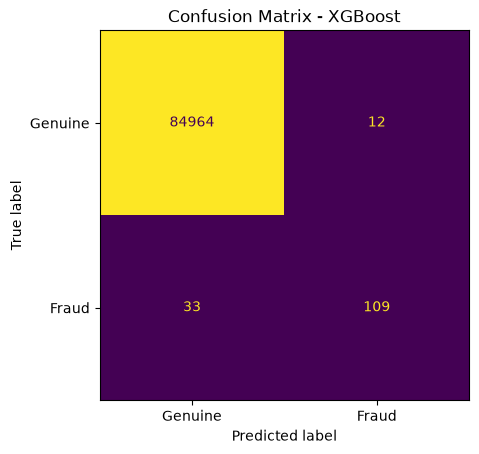

In [10]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Genuine", "Fraud"]
)

disp.plot(cmap="viridis", colorbar=False)

plt.title("Confusion Matrix - XGBoost")
plt.show()

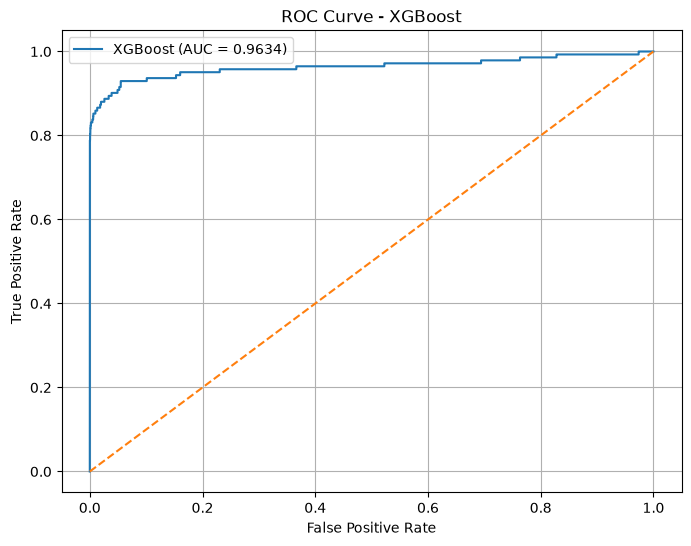

In [11]:
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {roc_auc_xgb:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - XGBoost")

plt.legend()
plt.grid()
plt.show()

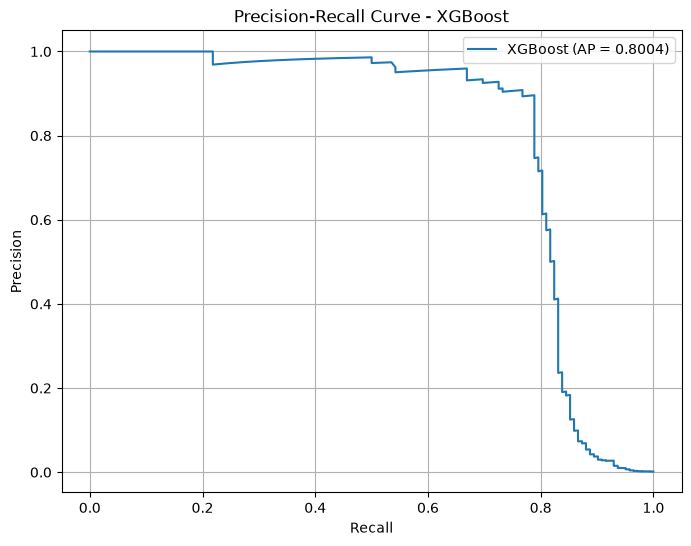

In [12]:
precision_xgb_curve, recall_xgb_curve, _ = precision_recall_curve(
    y_test,
    y_prob_xgb
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_xgb_curve,
    precision_xgb_curve,
    label=f"XGBoost (AP = {pr_auc_xgb:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve - XGBoost")

plt.legend()
plt.grid()
plt.show()

In [13]:
feature_importance_xgb = pd.DataFrame({
    "Feature": X_train_smote_xgb.columns,
    "Importance": model_xgb.feature_importances_
})

feature_importance_xgb = feature_importance_xgb.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_xgb.head(15))

,Feature,Importance
14,V14,0.656591
12,V12,0.050347
17,V17,0.036290
4,V4,0.033844
10,V10,0.016077
18,V18,0.015538
8,V8,0.015085
9,V9,0.014269
3,V3,0.012892
13,V13,0.012566


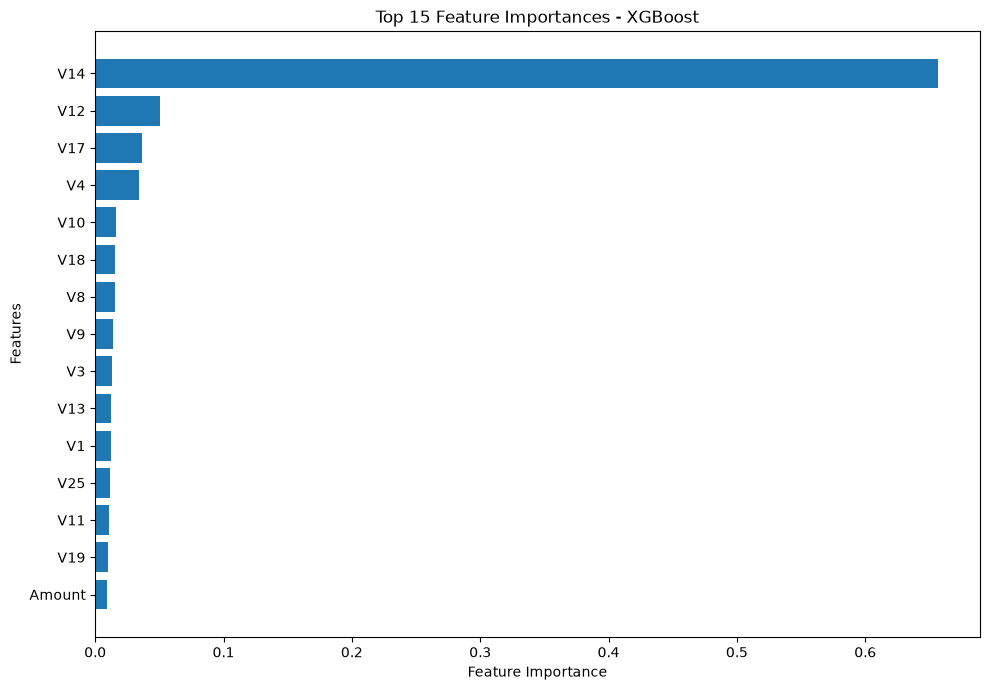

In [14]:
top_features_xgb = feature_importance_xgb.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features_xgb["Feature"],
    top_features_xgb["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.title("Top 15 Feature Importances - XGBoost")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [18]:
import pickle

# Save trained XGBoost model
with open("xgboost_model.pkl", "wb") as file:
    pickle.dump(model_xgb, file)

# Save selected threshold
with open("xgboost_threshold.pkl", "wb") as file:
    pickle.dump(final_threshold_xgb, file)

# Save feature columns
with open("feature_columns.pkl", "wb") as file:
    pickle.dump(list(X_train.columns), file)

print("All XGBoost files saved successfully!")

All XGBoost files saved successfully!
